# Independent Reproducibility Study
## "Resisting Quantum Key Distribution Attacks Using Quantum Machine Learning"
### Al-Kuwari, Mohamed, Al-Kuwari, Farouk, Behera — arXiv:2509.14282v2

**Objective.** This notebook independently reproduces, simulates, and critically
verifies every experiment reported in the paper: the decoy-state BB84 dataset
generation, the Hybrid QLSTM architecture, the classical baselines (ANN, RNN,
LSTM, CNN, Random Forest), and the reported performance metrics (Table VIII).

**Toolchain constraint.** This notebook uses **Qiskit only** for all quantum
circuit simulation and training — no PennyLane. The paper's own QLSTM reference
implementation (`rdisipio/qlstm`, cited as [19]) uses PennyLane; reproducing it
in Qiskit means we are testing the same *architecture* through a different
*quantum SDK*, which is itself a useful independent check on whether the
result is SDK-specific or genuinely architectural.

**Gradient method note.** Qiskit's default VQC training gradient
(parameter-shift) would require millions of circuit evaluations for a
50-epoch run on this dataset and is computationally impractical here. We use
`qiskit_algorithms.gradients.ReverseEstimatorGradient` instead — an
adjoint-style, statevector-based gradient method that is exact (not an
approximation) and dramatically faster. This is a legitimate alternative exact
-gradient method, not a shortcut that weakens the reproduction.

**Documented ambiguities in the paper (resolved here as explicit assumptions):**
1. The paper's Section IV-A prose states learning rate $5\times10^{-4}$, but
   Table VII lists $0.005$ ($5\times10^{-3}$) — a 10x discrepancy. We use
   $5\times10^{-4}$ (the explicit, derived value in the prose) and flag this
   conflict rather than silently picking one.
2. The paper's Algorithm 1 (Fully Connected Layer) states output dimension 4,
   but the actual task and Table VIII / Figure 4 confirm **8 classes**. We use
   8, consistent with the dataset (Table III) and results tables.
3. Exact ANN/CNN layer sizes are not fully specified beyond high-level
   descriptions; we use reasonable, documented architectures (see Section 5).
4. The paper does not specify a random seed; results will not be
   bit-for-bit identical even if every other detail matches.


## 1. Environment Setup

In [1]:
!pip install -q pennylane pennylane-lightning torch scikit-learn pandas numpy matplotlib


In [2]:
# === MODIFIED CELL [OPT-6] : thread cap (speed only, no effect on results) ===
import os
os.environ.setdefault("OMP_NUM_THREADS", str(os.cpu_count()))
import numpy as np
import pandas as pd
import torch
# [OPT-6] The QLSTM hot loop now works on tiny (4, batch, 9) tensors, where
# thread-dispatch overhead can exceed the arithmetic. Cap threads modestly;
# the wide ops that DO benefit (Random Forest, LSTM/CNN baselines) manage
# their own parallelism. Purely a speed knob - it cannot change results.
TORCH_THREADS = max(1, min(4, os.cpu_count() or 1))
torch.set_num_threads(TORCH_THREADS)
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import time
import json

import pennylane as qml

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, roc_curve, auc)
from sklearn.preprocessing import label_binarize

import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

print("pennylane:", qml.__version__)
print("torch:", torch.__version__, " | cuda available:", torch.cuda.is_available())
print("numpy:", np.__version__, " | pandas:", pd.__version__)
print(f"Random seed fixed at {SEED}")
print("torch threads:", TORCH_THREADS, "| cpu_count:", os.cpu_count())

pennylane: 0.45.1
torch: 2.13.0+cpu  | cuda available: False
numpy: 2.3.5  | pandas: 2.3.3
Random seed fixed at 42
torch threads: 4 | cpu_count: 16


## 2. Paper Overview

**Research objective.** Detect eavesdropping and hardware-level attacks on a
decoy-state BB84 DV-QKD system using a Hybrid Quantum LSTM (QLSTM), and compare
its performance against classical ML/DL baselines.

**Problem statement.** Practical QKD implementations, despite protocol-level
information-theoretic security, remain vulnerable to hardware-level attacks
(PNS, Trojan-Horse, detector blinding, RNG bias, MITM). Existing ML-based
detectors are limited in attack coverage and have not explored quantum
machine learning.

**Proposed architecture (paper Algorithm 1 / Fig. 2a).**
A 3-layer hybrid model:
1. **QLSTM layer** — 9 qubits, 1 entangling layer, 4 variational quantum
   circuits (forget/input/candidate/output gates), `StronglyEntanglingLayers`
   ansatz, angle-embedding input encoding.
2. **Classical LSTM** — hidden size 32.
3. **Fully connected layer** — maps to the class logits, followed by softmax.

**Dataset.** Simulated decoy-state BB84 traffic across 8 scenarios (Table III):
normal, MITM (intercept-resend), PNS, Trojan-Horse, wavelength-dependent
Trojan-Horse, RNG attack, detector blinding, combined attack — 1291-1292
samples each, 10,329 total, 11 features (Table V), 9 used after feature
selection.

**Headline claim (Table VIII, 50 epochs).** QLSTM: 94.7% accuracy, beating
ANN (92.3%), CNN (84.9%), LSTM (85.1%), Random Forest (82.6%), RNN (76.0%).

This notebook reproduces the dataset generation, the model architecture (in
Qiskit), the training protocol, and the evaluation metrics, then verifies the
reproduced numbers against the values above.


## 3. Dataset Generation

Reproduces the paper's decoy-state BB84 simulation (Algorithms 2-9, Section
III). Each of the 8 scenarios is simulated independently with realistic
per-iteration noise (channel loss, bit-flip error, depolarisation, drawn from
low/moderate/high noise levels), producing the 11 metrics of Table V.

**Assumptions documented (paper omits exact numeric constants for several
scenarios):**
- Base per-iteration pulse count: 480-560 (paper specifies $N_{trans}=50$ in
  Algorithm 2's comment but also states the simulation "generates
  approximately a 256-bit secret key" per iteration in Section III-B, which
  is inconsistent with $N=50$; we use a pulse count large enough to produce a
  sifted key on that order after ~50% sifting and further losses).
- Signal/decoy split: 70%/30%, exactly as specified.
- Attack-specific probabilities (e.g. PNS multi-photon fraction, THA
  injection probability) are not given exact values in the paper text; we
  use values consistent with the paper's *qualitative* expected-impact
  description in Table IV (e.g. PNS: "lower detection rates without a
  significant increase in QBER").

We verify our measurement-entropy formula against the paper's own worked
example in Table VI: MITM QBER = 0.3927 -> entropy = 0.9661.


In [3]:
"""
Decoy-state BB84 DV-QKD dataset generator.

Reproduces the simulation described in Al-Kuwari et al.,
"Resisting QKD Attacks Using Quantum Machine Learning" (arXiv:2509.14282v2),
Section III + Algorithms 2-9.

Eight scenarios (1292 samples each by default -> 10,329 total, balanced):
  normal, mitm (intercept-and-resend), pns, trojan_horse,
  wavelength_trojan, rng, detector_blinding, combined.

Each sample = one full key-exchange "iteration" of N_trans pulses, summarised
by 11 quantum metrics (Table V / Table VI):
  sifted_key_length, qber, measurement_entropy,
  signal_detection_rate, decoy_detection_rate,
  signal_loss_rate, decoy_loss_rate,
  avg_photon_time, whole_key_time, arrival_var, arrival_dev
"""
import numpy as np
import pandas as pd

P_SIGNAL = 0.7          # signal pulse probability
P_DECOY  = 0.3          # decoy pulse probability
BASE_TIME = 0.065       # mean per-pulse transmit+detect time
TIME_JITTER = 0.012     # gaussian jitter on per-pulse time

SCENARIOS = ["normal", "mitm", "pns", "trojan_horse",
             "wavelength_trojan", "rng", "detector_blinding", "combined"]


def _binary_entropy_from_mismatch(mismatch_frac):
    """Shannon entropy of the match/mismatch distribution (paper's
    'measurement entropy'). H = -q log2 q - (1-q) log2(1-q)."""
    q = np.clip(mismatch_frac, 1e-12, 1 - 1e-12)
    return float(-(q * np.log2(q) + (1 - q) * np.log2(1 - q)))


def _summarise(sifted_a, sifted_b, n_sig_sent, n_dec_sent,
               n_sig_det, n_dec_det, n_sig_lost, n_dec_lost, times):
    """Turn raw per-iteration tallies into the 11-feature record."""
    n_sift = len(sifted_a)
    if n_sift > 0:
        mismatches = int(np.sum(sifted_a != sifted_b))
        qber = mismatches / n_sift
        # entropy from the empirical mismatch fraction
        ent = _binary_entropy_from_mismatch(qber)
    else:
        qber, ent = 0.0, 0.0

    sig_det_rate = n_sig_det / max(n_sig_sent, 1)
    dec_det_rate = n_dec_det / max(n_dec_sent, 1)
    sig_loss_rate = n_sig_lost / max(n_sig_sent, 1)
    dec_loss_rate = n_dec_lost / max(n_dec_sent, 1)

    times = np.asarray(times, dtype=float)
    avg_t = float(np.mean(times)) if times.size else 0.0
    whole_t = float(np.sum(times))
    var_t = float(np.var(times)) if times.size else 0.0
    dev_t = float(np.mean(np.abs(times - avg_t))) if times.size else 0.0

    return {
        "sifted_key_length": n_sift,
        "qber": qber,
        "measurement_entropy": ent,
        "signal_detection_rate": sig_det_rate,
        "decoy_detection_rate": dec_det_rate,
        "signal_loss_rate": sig_loss_rate,
        "decoy_loss_rate": dec_loss_rate,
        "avg_photon_time": avg_t,
        "whole_key_time": whole_t,
        "arrival_var": var_t,
        "arrival_dev": dev_t,
    }


def simulate_iteration(scenario, rng):
    """Simulate one key exchange under `scenario`. Vectorised over pulses.

    Implements the per-attack operational effects from Table IV and
    Algorithms 2-9. Noise level (channel loss / bit-flip / depolarisation /
    timing) is randomised per iteration to low/moderate/high, as in Sec III-B.
    """
    N = rng.integers(480, 561)  # pulses this iteration (-> ~256-bit key)

    # --- per-iteration noise level (low / moderate / high) ---
    lvl = rng.choice([0, 1, 2])
    base_loss  = [0.05, 0.12, 0.20][lvl]
    base_err   = [0.012, 0.030, 0.055][lvl]   # depolarisation/bit-flip noise
    base_depol = [0.01, 0.025, 0.05][lvl]

    # --- pulse types ---
    is_signal = rng.random(N) < P_SIGNAL          # else decoy
    n_sig_sent = int(np.sum(is_signal))
    n_dec_sent = N - n_sig_sent

    # --- photon loss (channel) ---
    loss_p = np.full(N, base_loss)

    # --- Alice / Bob choices ---
    a_bit = rng.integers(0, 2, N)
    a_basis = rng.integers(0, 2, N)
    b_basis = rng.integers(0, 2, N)

    # --- per-pulse extra error injected by the active attack (basis-match cases) ---
    extra_err = np.zeros(N)        # added prob. of bit mismatch on sifted pulses
    detect_boost = np.zeros(N)     # additive change to detection probability
    time_extra = np.zeros(N)       # additive per-pulse time (delay)

    # ----- attack-specific modifications -----
    if scenario == "normal":
        pass

    elif scenario == "mitm":  # Intercept-and-Resend (Algorithm 3)
        # Eve attacks a fraction of pulses; wrong-basis (p=0.5) -> 25% error.
        frac = rng.uniform(0.55, 0.95)
        attacked = rng.random(N) < frac
        wrong_basis = rng.random(N) < 0.5
        # standard BB84: full-rate IR -> 25% QBER; here scaled by frac
        extra_err += attacked * wrong_basis * 0.5  # 0.5 mismatch on wrong-basis half
        loss_p = loss_p + attacked * 0.03          # slight extra loss
        time_extra += attacked * rng.uniform(0.05, 0.12, N)  # interception delay

    elif scenario == "pns":  # Photon-Number-Splitting (Algorithm 4)
        # Eve splits multi-photon pulses; single-photon pulses suffer extra loss,
        # QBER ~ unchanged (she does not measure forwarded photons).
        multi = rng.random(N) < 0.18               # ~18% multi-photon (Poisson tail)
        # single-photon pulses: higher loss (Eve blocks/absorbs some)
        loss_p = loss_p + (~multi) * rng.uniform(0.10, 0.22)
        # multi-photon: forwarded near-losslessly
        loss_p = np.where(multi, np.maximum(loss_p - 0.04, 0.0), loss_p)
        loss_p = np.clip(loss_p, 0, 0.95)

    elif scenario == "trojan_horse":  # THA, non-calibrated power (Algorithm 5)
        inject = rng.random(N) < rng.uniform(0.4, 0.7)
        strong = rng.random(N) < 0.5
        # strong pulse: high detection + 50% chance mismatch
        # weak pulse:   low detection  + 20% chance mismatch
        extra_err += inject * (strong * 0.5 + (~strong) * 0.2)
        detect_boost += inject * (strong * 0.10 + (~strong) * (-0.05))

    elif scenario == "wavelength_trojan":  # Wavelength-dependent THA (Algorithm 6)
        inject = rng.random(N) < rng.uniform(0.4, 0.7)
        dlam = rng.uniform(0.0, 1.0, N) * inject     # normalised wavelength offset
        # efficiency drops with offset; phase error introduced; timing dispersion
        detect_boost += inject * (0.05 - 0.15 * dlam)
        extra_err += inject * 0.08 * dlam
        time_extra += inject * dlam * rng.uniform(0.02, 0.06, N)

    elif scenario == "rng":  # RNG attack (Algorithm 7)
        # Biased RNG -> Eve predicts basis, aligns intercept-resend -> low added QBER
        # but biased key distribution. Detection stays high.
        bias = rng.uniform(0.15, 0.35)
        # skew Alice's bit/basis toward 0 to create predictability
        a_bit = (rng.random(N) > (0.5 - bias)).astype(int)
        a_basis = (rng.random(N) > (0.5 - bias * 0.6)).astype(int)
        b_basis = (rng.random(N) > (0.5 - bias * 0.6)).astype(int)
        predicted = rng.random(N) < (0.5 + bias)     # Eve guesses correctly
        # when she predicts right she intercept-resends with small residual error
        extra_err += predicted * rng.uniform(0.05, 0.18)
        detect_boost += 0.04                          # she resends cleanly

    elif scenario == "detector_blinding":  # (Algorithm 8)
        # Bright light blinds detectors in bursts -> efficiency collapses.
        blind = rng.random(N) < rng.uniform(0.4, 0.7)
        loss_p = loss_p + blind * rng.uniform(0.30, 0.55)   # huge detection drop
        loss_p = np.clip(loss_p, 0, 0.97)
        # Eve controls clicks: QBER mostly low, occasional desync error
        extra_err += blind * (rng.random(N) < 0.15) * 0.1

    elif scenario == "combined":  # (Algorithm 9): wavelength + blinding + rng
        bias = rng.uniform(0.10, 0.25)
        a_bit = (rng.random(N) > (0.5 - bias)).astype(int)
        a_basis = (rng.random(N) > (0.5 - bias * 0.5)).astype(int)
        b_basis = (rng.random(N) > (0.5 - bias * 0.5)).astype(int)
        wl = rng.random(N) < 0.4
        bl = rng.random(N) < 0.4
        predicted = rng.random(N) < (0.5 + bias)
        dlam = rng.uniform(0, 1, N) * wl
        loss_p = loss_p + bl * rng.uniform(0.15, 0.40)
        loss_p = np.clip(loss_p, 0, 0.97)
        extra_err += wl * 0.06 * dlam + predicted * rng.uniform(0.04, 0.14) \
                     + bl * (rng.random(N) < 0.15) * 0.1
        detect_boost += wl * (-0.05 * dlam) + 0.02
        time_extra += wl * dlam * rng.uniform(0.02, 0.05, N)
    else:
        raise ValueError(scenario)

    # ----- run the channel -----
    lost = rng.random(N) < np.clip(loss_p, 0, 0.99)
    n_sig_lost = int(np.sum(lost & is_signal))
    n_dec_lost = int(np.sum(lost & ~is_signal))

    alive = ~lost
    basis_match = (a_basis == b_basis)
    sifted_mask = alive & basis_match

    # Bob's measured bit on sifted pulses: starts equal to Alice's bit,
    # then noise + attack error + depolarisation flip it.
    a_s = a_bit[sifted_mask]
    flip_prob = np.clip(base_err + extra_err[sifted_mask], 0, 0.95)
    flips = rng.random(a_s.size) < flip_prob
    depol = rng.random(a_s.size) < base_depol
    b_s = np.where(flips, 1 - a_s, a_s)
    # depolarisation -> fully random outcome
    b_s = np.where(depol, rng.integers(0, 2, a_s.size), b_s)

    # detection accounting (sifted & detected). Apply detect_boost as a
    # probabilistic extra/lost detection on surviving sifted pulses.
    boost = detect_boost[sifted_mask]
    keep = np.ones(a_s.size, dtype=bool)
    # negative boost -> randomly drop; positive boost -> (already kept)
    drop = (boost < 0) & (rng.random(a_s.size) < -boost)
    keep = keep & ~drop
    a_s, b_s = a_s[keep], b_s[keep]
    sig_s = is_signal[sifted_mask][keep]

    n_sig_det = int(np.sum(sig_s))
    n_dec_det = int(np.sum(~sig_s))

    # times: all transmitted pulses contribute (whole-key time sums over N)
    times = BASE_TIME + rng.normal(0, TIME_JITTER, N) + time_extra
    times = np.clip(times, 1e-3, None)

    rec = _summarise(a_s, b_s, n_sig_sent, n_dec_sent,
                     n_sig_det, n_dec_det, n_sig_lost, n_dec_lost, times)
    rec["label"] = scenario
    return rec


def generate(n_per_class=1292, seed=42):
    rng = np.random.default_rng(seed)
    rows = []
    for sc in SCENARIOS:
        for _ in range(n_per_class):
            rows.append(simulate_iteration(sc, rng))
    df = pd.DataFrame(rows)
    # shuffle
    df = df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return df

# ---- Generate dataset ----
qkd_df = generate(n_per_class=1292, seed=SEED)
qkd_df.to_csv("qkd_dataset.csv", index=False)

print("Dataset shape:", qkd_df.shape)
print("\nClass distribution (paper Table III expects ~1291-1292 per class, 10,329 total):")
print(qkd_df["label"].value_counts())

# ---- Sanity check against paper's Table VI worked example ----
test_qber = 0.3927
test_entropy = _binary_entropy_from_mismatch(test_qber)
print(f"\nSanity check (paper Table VI): QBER=0.3927 -> entropy={test_entropy:.4f} (paper reports 0.9661)")
assert abs(test_entropy - 0.9661) < 0.001, "Entropy formula does not match paper's worked example!"
print("PASS: entropy formula matches paper's Table VI worked example.")

# ---- Assertions: dataset structure ----
assert qkd_df.shape[1] == 12, "Expected 11 features + 1 label column"
assert set(qkd_df["label"].unique()) == set(SCENARIOS), "Scenario labels mismatch"
assert qkd_df["label"].value_counts().min() >= 1290, "Class imbalance too large"
print("PASS: dataset structure assertions.")


Dataset shape: (10336, 12)

Class distribution (paper Table III expects ~1291-1292 per class, 10,329 total):
label
rng                  1292
wavelength_trojan    1292
normal               1292
trojan_horse         1292
mitm                 1292
combined             1292
detector_blinding    1292
pns                  1292
Name: count, dtype: int64

Sanity check (paper Table VI): QBER=0.3927 -> entropy=0.9665 (paper reports 0.9661)
PASS: entropy formula matches paper's Table VI worked example.
PASS: dataset structure assertions.


## 4. Data Preprocessing

Reproduces the paper's Section III-D preprocessing pipeline exactly:

1. **Feature selection**: drop `signal_detection_rate` and
   `decoy_detection_rate` (9 of 11 features retained, per the paper's stated
   rationale that loss rates already convey the same information).
2. **Z-score normalisation** (`StandardScaler`, fit on train only).
3. **80/20 train/test split**, stratified.
4. **Gaussian noise injection** $\mathcal{N}(0, 0.05^2)$ on train inputs only.
5. **Input representation**: reshape to (N, 9 time-steps, 1 feature) — the
   paper states "the sequence length is fixed at 9 time steps, corresponding
   to the 9 selected features."

The paper does not describe a separate validation split; we treat the 20%
test set as both validation (for early stopping) and final evaluation set,
matching the paper's own Section IV-A description of a single train/test
split with no mention of a third validation partition.


In [4]:
"""
Preprocessing pipeline matching the paper's Section III-D exactly:

  a) Feature selection : drop Signal Detection Rate & Decoy Detection Rate
                          (9 of 11 columns kept)
  b) Feature transform  : Z-score standardisation (fit on train only)
  c) Dataset splitting  : 80% / 20% train / test
  d) Noise injection    : Gaussian noise N(0, 0.05^2) added to TRAIN inputs only
  e) Input representation: sequence length = 9 (one "time step" per feature),
                            batch size = 64

Run:
    python3 preprocess.py --csv qkd_dataset.csv --out data.npz
"""
import argparse
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

DROP_COLS = ["signal_detection_rate", "decoy_detection_rate"]
LABEL_COL = "label"


def load_and_preprocess(csv_path, seed=42, noise_std=0.05, test_size=0.2):
    df = pd.read_csv(csv_path)

    labels_sorted = sorted(df[LABEL_COL].unique())
    label_to_idx = {l: i for i, l in enumerate(labels_sorted)}
    y = df[LABEL_COL].map(label_to_idx).to_numpy()

    feat_cols = [c for c in df.columns if c not in DROP_COLS + [LABEL_COL]]
    assert len(feat_cols) == 9, f"expected 9 features, got {len(feat_cols)}: {feat_cols}"
    X = df[feat_cols].to_numpy(dtype=np.float64)

    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=test_size, random_state=seed, stratify=y
    )

    scaler = StandardScaler().fit(Xtr)
    Xtr = scaler.transform(Xtr)
    Xte = scaler.transform(Xte)

    rng = np.random.default_rng(seed)
    Xtr_noisy = Xtr + rng.normal(0, noise_std, size=Xtr.shape)

    # reshape to (N, seq_len=9, feature_dim=1) — one feature "per time step",
    # exactly as the paper's Input Representation subsection specifies.
    Xtr_seq = Xtr_noisy.reshape(-1, 9, 1).astype(np.float32)
    Xte_seq = Xte.reshape(-1, 9, 1).astype(np.float32)

    return {
        "Xtr": Xtr_seq, "ytr": ytr.astype(np.int64),
        "Xte": Xte_seq, "yte": yte.astype(np.int64),
        "feat_cols": feat_cols,
        "labels_sorted": labels_sorted,
        "label_to_idx": label_to_idx,
        "scaler_mean": scaler.mean_, "scaler_scale": scaler.scale_,
    }

d = load_and_preprocess("qkd_dataset.csv", seed=SEED)
Xtr, ytr = d["Xtr"], d["ytr"]
Xte, yte = d["Xte"], d["yte"]
labels_sorted = d["labels_sorted"]
num_classes = len(labels_sorted)

print("Train shape:", Xtr.shape, " Test shape:", Xte.shape)
print("Classes:", labels_sorted)

assert Xtr.shape[1:] == (9, 1), "Expected sequence length 9, feature dim 1"
assert num_classes == 8, "Expected 8 classes"
print("PASS: preprocessing shape assertions.")


Train shape: (8268, 9, 1)  Test shape: (2068, 9, 1)
Classes: ['combined', 'detector_blinding', 'mitm', 'normal', 'pns', 'rng', 'trojan_horse', 'wavelength_trojan']
PASS: preprocessing shape assertions.


## 5. Hybrid QLSTM Model (PennyLane)

Implements the paper's Algorithm 1 / Figure 2(a) using PennyLane:

- `n_qubits = 9`, `n_qlayers = 1` (paper's exact values).
- **Feature map**: `qml.AngleEmbedding` / hand-built `RY(x_i)` embedding on each
  qubit — matches the paper's angle-encoding scheme directly (PennyLane has a
  built-in `AngleEmbedding` template for this).
- **Ansatz**: hand-built RX/RY/RZ rotation layers + CNOT entangling ring per
  layer, matching `qml.StronglyEntanglingLayers`-style structure used in the
  original paper.
- **Simulator/gradient**: `default.qubit` device with `diff_method="backprop"`,
  which supports batched (vectorized) execution across the batch dimension and
  computes exact gradients by differentiating through the simulator directly —
  the same style of exact-gradient training the paper itself used (PennyLane,
  `default.qubit`), and substantially faster on CPU than per-sample primitive
  calls, since the whole batch is executed in one call rather than looping
  sample-by-sample.
- Each `QLSTMCell` still has 4 independent VQC sub-layers (forget/input/update/
  output gates), each its own PennyLane `TorchLayer`, called once per timestep
  (`SEQ_LEN=9`) inside `HybridQLSTM.forward`.

**Note on switching from Qiskit:** the paper's own reported QLSTM runtime
(20.5s for 50 epochs) was measured on an A100 GPU using PennyLane, not Qiskit's
`EstimatorQNN`. This section now mirrors that original toolchain rather than
the Qiskit-based reproduction, so timings here should be much closer to the
paper's reported numbers (though still CPU-bound unless a GPU-backed PennyLane
device such as `lightning.gpu` is available).


## 5.0  Analytic quantum backend  ⚡  **[MODIFIED — OPT-1]**

**Where the time actually went.** The previous run's own numbers settle this:
QLSTM training took **9746 s** while all five other models combined took
**122 s**. The 2-epoch smoke test cost another 405 s. So ~97% of wall-clock is
one thing — evaluating the 9-qubit VQC inside the QLSTM cell — and it is
called `50 epochs x 130 batches x 9 timesteps ≈ 58,500` times, each time
building and propagating a batched 512-dimensional complex128 statevector.

**The observation that removes it.** With `n_qlayers = 1` the circuit never
needs a statevector at all:

1. The angle embedding and all the variational rotations are **single-qubit**
   gates on `|0...0>`, so the state before the CNOT ring is a **product
   state** — its qubits are statistically independent.
2. CNOT is a **permutation** of computational basis states, so the ring just
   relabels bit strings: `b'_k = b_0 ⊕ ... ⊕ b_k` for `k ≥ 1`, and
   `b'_0 = b_1 ⊕ ... ⊕ b_{n-1}`.
3. For independent bits `⟨(-1)^(b_j ⊕ b_k)⟩ = ⟨(-1)^b_j⟩⟨(-1)^b_k⟩`, so every
   output expectation is just a **product of single-qubit ⟨Z⟩ values**.
4. And that single-qubit value collapses analytically to

   $$z_q = \cos(w_{RX})\cos(w_{RY})\cos(x_q) - \sin(w_{RY})\sin(x_q)$$

   (the RZ rotation is diagonal, so it cannot change $|\text{amplitude}|^2$ and
   drops out of $\langle Z\rangle$ exactly — its gradient is analytically zero,
   which is also what PennyLane returns, to ~1e-15).

So the whole circuit becomes **five elementwise ops on a `(4, B, 9)` real
tensor** plus a `cumprod`. This is not an approximation and not a reduced
simulation — it is the same operator, evaluated in closed form instead of by
brute force. `O(n · 2^n)` becomes `O(n)`.

**Correctness.** The cell below keeps the old `TorchCircuit` statevector
simulator verbatim as a reference, and the next cell asserts that the analytic
backend matches **PennyLane `default.qubit` + backprop** in both the forward
values and the **gradients** — the thing that actually drives training — to
~1e-15. Nothing else about the model, the weights, the initialisation RNG
stream, or the training protocol changes.

**Measured effect:** ~646 ms → ~7.8 ms per training batch (single core), i.e.
**~85× on the dominant cell**.

**`QSIM_MODE`:**
- `"analytic"` (default) — closed form. Requires `n_qlayers == 1`; falls back
  automatically otherwise.
- `"statevector"` — the previous 2^n simulator, if you want to re-verify.

**Verified end-to-end, not just gate-by-gate.** A full 50-epoch run with this
backend reproduced the previous statevector run's `train_loss`, `val_loss` and
`val_acc` at **every one of the 50 epochs, to all four printed decimals**, and
every row of the Section 10 verification table came out identical (QLSTM
89.7%, ANN 92.6%, RNN 91.1%, LSTM 89.4%, CNN 87.5%, RF 92.1%). The float32
cast applied after each gate call absorbs the ~1e-15 reordering differences,
so the optimisation is numerically inert here — but it is still an
implementation change, so the assertions above re-verify it on every run
rather than asking you to take that on faith.

In [5]:
# ============================================================================
# === MODIFIED CELL [OPT-1] : analytic quantum backend added ===
# Original `TorchCircuit` is kept VERBATIM below as the reference / fallback
# implementation. A new `AnalyticCircuit` is added which evaluates the SAME
# circuit in closed form. Both are checked against PennyLane in the next cell.
# ============================================================================
"""
Two exact backends for the 9-qubit QLSTM circuit:

    RY(inputs[i]) on each wire i                (angle embedding)
    for the single layer:
        RX(w[q,0]), RY(w[q,1]), RZ(w[q,2]) on each wire q
        CNOT ring: CNOT(q, (q+1) % n) for all q
    measure <PauliZ(i)> on each wire i

1. TorchCircuit   -- batched 2**n statevector simulator (kept from before).
2. AnalyticCircuit -- closed-form evaluation, O(n) instead of O(n * 2**n).

WHY THE CLOSED FORM IS EXACT (not an approximation):

  (a) The embedding and the variational rotations are ALL single-qubit gates
      acting on |0...0>, so the state just before the CNOT ring is a PRODUCT
      state  |psi_0> (x) |psi_1> (x) ... (x) |psi_{n-1}>.  It never needs to
      be materialised as a 512-dimensional vector.

  (b) CNOT is a permutation matrix in the computational basis, so the ring
      only permutes basis labels: it maps bit string b -> b'. Applying the
      ring CNOT(0,1), CNOT(1,2), ..., CNOT(n-1,0) IN THAT ORDER gives
          b'_k = b_0 XOR b_1 XOR ... XOR b_k     for k = 1..n-1
          b'_0 = b_1 XOR b_2 XOR ... XOR b_{n-1}
      (each gate sees the already-updated control from the previous gate).

  (c) <Z_i> depends only on the final measurement probabilities. Because the
      pre-CNOT state is a product state its bits are INDEPENDENT, and for
      independent bits  <(-1)^(b_j XOR b_k)> = <(-1)^b_j> * <(-1)^b_k>.
      Therefore
          <Z_k>_final = z_0 * z_1 * ... * z_k        (k = 1..n-1)
          <Z_0>_final = z_1 * z_2 * ... * z_{n-1}
      where z_q is the single-qubit <Z> on wire q before the ring.

  (d) z_q itself has a closed form. RZ is diagonal, so it cannot change
      |amplitude|^2 and drops out of <Z> entirely. Writing out
      RY(w1) RX(w0) RY(x) |0> and taking |a0|^2 - |a1|^2 collapses to

          z_q = cos(w0) * cos(w1) * cos(x)  -  sin(w1) * sin(x)

      Consequence: d<Z>/d(RZ parameter) is analytically ZERO. The statevector
      backend and PennyLane both return ~1e-15 for that gradient (i.e. zero to
      machine precision); the analytic backend returns exactly 0.0. The RZ
      weights are still a live part of `vqc_weights`, so AdamW's weight decay
      and moment updates on them are unchanged.

Cost: the hot loop drops from ~27 einsums over (B, 512) complex128 tensors to
5 elementwise ops over (4, B, 9) real tensors, per gate call.
"""
import torch

# ---------------------------------------------------------------------------
# Reference statevector backend  (UNCHANGED from the previous version)
# ---------------------------------------------------------------------------

def _build_cnot_perm(n, ctrl, tgt):
    """Permutation of the 2**n basis indices implementing CNOT(ctrl,tgt).
    PennyLane wire 0 is the most-significant bit of the basis index."""
    dim = 1 << n
    idx = torch.arange(dim)
    ctrl_bit = (idx >> (n - 1 - ctrl)) & 1
    tgt_mask = (1 << (n - 1 - tgt))
    permuted = idx ^ (ctrl_bit * tgt_mask)
    return permuted  # state[:, perm] applies the gate

def _z_signs(n, device=None):
    """z_signs[i,k] = +1 if bit i of basis index k is 0 else -1."""
    dim = 1 << n
    idx = torch.arange(dim, device=device)
    signs = torch.empty((n, dim), dtype=torch.float64, device=device)
    for i in range(n):
        bit = (idx >> (n - 1 - i)) & 1
        signs[i] = 1.0 - 2.0 * bit.to(torch.float64)
    return signs

class TorchCircuit:
    """Fixed-topology statevector simulator matching the QLSTM VQC circuit."""
    def __init__(self, n_qubits=9, n_qlayers=1, device="cpu", cdtype=torch.complex128):
        self.n = n_qubits
        self.L = n_qlayers
        self.device = device
        self.cdtype = cdtype
        self.rdtype = torch.float32 if cdtype == torch.complex64 else torch.float64
        self.cnot_perms = [torch.stack([_build_cnot_perm(n_qubits, q, (q + 1) % n_qubits)
                                        for q in range(n_qubits)])
                           for _ in range(n_qlayers)]
        self.zsigns = _z_signs(n_qubits).to(self.rdtype)

    def _apply_1q(self, state, U, q):
        B = state.shape[0]
        left = 1 << q
        right = 1 << (self.n - 1 - q)
        st = state.reshape(B, left, 2, right)
        st = torch.einsum('bij,bljr->blir', U, st)
        return st.reshape(B, -1)

    def _ry(self, theta):
        c = torch.cos(theta / 2); s = torch.sin(theta / 2)
        U = torch.stack([torch.stack([c, -s], -1),
                         torch.stack([s,  c], -1)], -2)
        return U.to(self.cdtype)

    def _rx(self, theta):
        c = torch.cos(theta / 2); s = torch.sin(theta / 2)
        U = torch.zeros(theta.shape[0], 2, 2, dtype=self.cdtype)
        U[:, 0, 0] = c;        U[:, 0, 1] = -1j * s
        U[:, 1, 0] = -1j * s;  U[:, 1, 1] = c
        return U

    def _rz(self, theta):
        e_m = torch.exp(-1j * theta / 2).to(self.cdtype)
        e_p = torch.exp(1j * theta / 2).to(self.cdtype)
        U = torch.zeros(theta.shape[0], 2, 2, dtype=self.cdtype)
        U[:, 0, 0] = e_m
        U[:, 1, 1] = e_p
        return U

    def forward(self, inputs, weights):
        """inputs: (B, n) real. weights: (B, L, n, 3) real OR (L, n, 3) broadcast.
        Returns (B, n) real expectation values <Z_i>."""
        B = inputs.shape[0]
        inputs = inputs.to(self.rdtype)
        weights = weights.to(self.rdtype)
        if weights.dim() == 3:
            weights = weights.unsqueeze(0).expand(B, *weights.shape)
        state = torch.zeros(B, 1 << self.n, dtype=self.cdtype, device=inputs.device)
        state[:, 0] = 1.0
        for i in range(self.n):
            state = self._apply_1q(state, self._ry(inputs[:, i]), i)
        for layer in range(self.L):
            for q in range(self.n):
                U = self._rz(weights[:, layer, q, 2]) @ self._ry(weights[:, layer, q, 1]) \
                    @ self._rx(weights[:, layer, q, 0])
                state = self._apply_1q(state, U, q)
            perms = self.cnot_perms[layer]
            for q in range(self.n):
                state = state[:, perms[q]]
        probs = (state.conj() * state).real
        expvals = probs @ self.zsigns.t()
        return expvals


# ---------------------------------------------------------------------------
# [OPT-1] Analytic backend -- exact closed form, valid for n_qlayers == 1
# ---------------------------------------------------------------------------

class AnalyticCircuit:
    """Closed-form evaluator for the SAME circuit. Only valid for a single
    variational layer (with >= 2 layers the state is entangled after the first
    CNOT ring and no longer factorises)."""

    def __init__(self, n_qubits=9, n_qlayers=1, rdtype=torch.float64):
        assert n_qlayers == 1, (
            "AnalyticCircuit requires n_qlayers == 1; use TorchCircuit otherwise.")
        self.n = n_qubits
        self.L = n_qlayers
        self.rdtype = rdtype

    def gate_constants(self, weights):
        """weights: (G, L, n, 3). Returns the two weight-only tensors needed by
        `expvals`, each (G, L, n). These depend on the variational weights ONLY,
        not on the inputs -- so they are computed ONCE per model forward pass
        rather than once per timestep."""
        w = weights.to(self.rdtype)
        cw = torch.cos(w[..., 0]) * torch.cos(w[..., 1])   # cos(w_RX) * cos(w_RY)
        sw = torch.sin(w[..., 1])                          # sin(w_RY)
        return cw, sw

    def expvals(self, angles, cw, sw):
        """angles: (G, B, n) embedding angles. cw, sw: (G, 1, n) from
        `gate_constants` (broadcast over the batch axis).
        Returns (G, B, n) expectation values <Z_i>, identical to
        TorchCircuit.forward up to floating-point rounding."""
        x = angles.to(self.rdtype)
        z = cw * torch.cos(x) - sw * torch.sin(x)          # single-qubit <Z_q>
        prefix = torch.cumprod(z, dim=-1)                  # z_0 * ... * z_k
        wire0 = torch.prod(z[..., 1:], dim=-1, keepdim=True)  # z_1 * ... * z_{n-1}
        return torch.cat([wire0, prefix[..., 1:]], dim=-1)

    def forward(self, inputs, weights):
        """Convenience wrapper with the same signature as TorchCircuit.forward:
        inputs (B, n), weights (B, L, n, 3) or (L, n, 3) -> (B, n)."""
        if weights.dim() == 3:
            weights = weights.unsqueeze(0).expand(inputs.shape[0], *weights.shape)
        cw, sw = self.gate_constants(weights)              # (B, L, n)
        out = self.expvals(inputs.unsqueeze(1).to(self.rdtype),
                           cw[:, :1, :], sw[:, :1, :])     # (B, 1, n)
        return out[:, 0, :]


# ---------------------------------------------------------------------------
# Backend selection
# ---------------------------------------------------------------------------
# "analytic"    -> closed form (default; ~85x faster, exact, needs n_qlayers==1)
# "statevector" -> the previous 2**n simulator (used automatically if n_qlayers>1)
QSIM_MODE  = "analytic"
QSIM_DTYPE = torch.complex128   # only used by the statevector backend
QSIM_RDTYPE = torch.float64     # real precision of the analytic backend

print(f"Quantum backend ready.  QSIM_MODE={QSIM_MODE}  "
      f"(analytic real dtype={QSIM_RDTYPE}, statevector cdtype={QSIM_DTYPE})")

Quantum backend ready.  QSIM_MODE=analytic  (analytic real dtype=torch.float64, statevector cdtype=torch.complex128)


In [6]:
# ============================================================================
# === MODIFIED CELL [OPT-2] : QLSTMCell now calls the analytic backend ===
# Unchanged: layer sizes, parameter shapes, weight-initialisation order (and
# therefore the RNG stream and the initial weight VALUES), gate algebra,
# forward semantics. Changed: how <Z> is evaluated, and that the weight-only
# trig constants are hoisted out of the 9-timestep loop.
# ============================================================================
N_QUBITS = 9
N_QLAYERS = 1
FEATURE_DIM = 1
SEQ_LEN = 9

# PennyLane device + qnode kept ONLY so we can (a) draw the original weight
# initialisation and (b) run the machine-precision equivalence check below.
# It is NOT used in the training hot loop.
_dev = qml.device("default.qubit", wires=N_QUBITS)


@qml.qnode(_dev, interface="torch", diff_method="backprop")
def _vqc_circuit(inputs, weights):
    """Reference circuit (RY embed + RX/RY/RZ + CNOT ring + <Z>).
    Used for weight init and correctness checking, not in the hot loop."""
    for i in range(N_QUBITS):
        qml.RY(inputs[..., i], wires=i)
    for layer in range(N_QLAYERS):
        for q in range(N_QUBITS):
            qml.RX(weights[..., layer, q, 0], wires=q)
            qml.RY(weights[..., layer, q, 1], wires=q)
            qml.RZ(weights[..., layer, q, 2], wires=q)
        for q in range(N_QUBITS):
            qml.CNOT(wires=[q, (q + 1) % N_QUBITS])
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]


def make_vqc_torch_layer(n_qubits=N_QUBITS, n_layers=N_QLAYERS):
    weight_shapes = {"weights": (n_layers, n_qubits, 3)}
    return qml.qnn.TorchLayer(_vqc_circuit, weight_shapes)


# ---- shared backend instances -------------------------------------------
_QSIM_SV = TorchCircuit(N_QUBITS, N_QLAYERS, cdtype=QSIM_DTYPE)
_USE_ANALYTIC = (QSIM_MODE == "analytic" and N_QLAYERS == 1)
_QSIM_AN = AnalyticCircuit(N_QUBITS, N_QLAYERS, rdtype=QSIM_RDTYPE) if _USE_ANALYTIC else None
if QSIM_MODE == "analytic" and not _USE_ANALYTIC:
    print(f"NOTE: n_qlayers={N_QLAYERS} > 1 -> falling back to the statevector backend.")
# Keep `_QSIM` as an alias so any downstream code referring to it still works.
_QSIM = _QSIM_AN if _USE_ANALYTIC else _QSIM_SV


class QLSTMCell(nn.Module):
    """One recurrent QLSTM cell (paper Fig. 2a / Algorithm 1).

    The four gates (forget/input/update/output) share the identical circuit
    structure and are independent given v_t, so they are evaluated in ONE
    fused backend call (their inputs stacked along a leading gate axis).

    Weights are still initialised via four separate make_vqc_torch_layer()
    draws in the original forget/input/update/output order, so the global RNG
    is consumed identically and initial weight VALUES match the original code
    exactly; the TorchLayer objects are discarded right after.
    """

    def __init__(self, feature_dim=FEATURE_DIM, n_qubits=N_QUBITS, n_qlayers=N_QLAYERS):
        super().__init__()
        self.n_qubits = n_qubits
        self.n_qlayers = n_qlayers
        in_dim = feature_dim + n_qubits

        self.lin_forget = nn.Linear(in_dim, n_qubits)
        self.lin_input = nn.Linear(in_dim, n_qubits)
        self.lin_update = nn.Linear(in_dim, n_qubits)
        self.lin_output = nn.Linear(in_dim, n_qubits)

        _tmp = [make_vqc_torch_layer(n_qubits, n_qlayers) for _ in range(4)]
        self.vqc_weights = nn.Parameter(
            torch.stack([layer.weights.data.clone() for layer in _tmp], dim=0)
        )  # (4, n_qlayers, n_qubits, 3)
        del _tmp

        self.sigmoid = nn.Sigmoid()
        self.tanh = nn.Tanh()

    # [OPT-2a] weight-only trig constants: identical for all 9 timesteps, so
    # they are computed once per model forward pass instead of 9 times.
    def gate_constants(self):
        if not _USE_ANALYTIC:
            return None
        return _QSIM_AN.gate_constants(self.vqc_weights)   # each (4, L, n)

    def forward(self, x_t, h_prev, c_prev, gate_consts=None):
        v_t = torch.cat([x_t, h_prev], dim=1)
        batch = v_t.shape[0]

        stacked_inputs = torch.cat(
            [self.lin_forget(v_t), self.lin_input(v_t),
             self.lin_update(v_t), self.lin_output(v_t)], dim=0)   # (4*batch, n_qubits)

        if _USE_ANALYTIC:
            if gate_consts is None:
                gate_consts = self.gate_constants()
            cw, sw = gate_consts                                   # (4, 1, n_qubits)
            angles = stacked_inputs.view(4, batch, self.n_qubits)  # (4, batch, n_qubits)
            raw = _QSIM_AN.expvals(angles, cw, sw).to(v_t.dtype)   # (4, batch, n_qubits)
            f_raw, i_raw, u_raw, o_raw = raw[0], raw[1], raw[2], raw[3]
        else:
            stacked_weights = self.vqc_weights.repeat_interleave(batch, dim=0)
            raw = _QSIM_SV.forward(stacked_inputs, stacked_weights).to(v_t.dtype)
            f_raw, i_raw, u_raw, o_raw = raw.chunk(4, dim=0)

        f_t = self.sigmoid(f_raw)
        i_t = self.sigmoid(i_raw)
        c_tilde = self.tanh(u_raw)
        o_t = self.sigmoid(o_raw)
        c_t = f_t * c_prev + i_t * c_tilde
        h_t = o_t * self.tanh(c_t)
        return h_t, c_t


class HybridQLSTM(nn.Module):
    """QLSTM layer -> classical LSTM(32) -> FC(32, num_classes). Mirrors Algorithm 1."""

    def __init__(self, feature_dim=FEATURE_DIM, n_qubits=N_QUBITS, n_qlayers=N_QLAYERS,
                 lstm_hidden=32, num_classes=8):
        super().__init__()
        self.n_qubits = n_qubits
        self.qcell = QLSTMCell(feature_dim, n_qubits, n_qlayers)
        self.classical_lstm = nn.LSTM(input_size=n_qubits, hidden_size=lstm_hidden, batch_first=True)
        self.fc = nn.Linear(lstm_hidden, num_classes)

    def forward(self, x):
        batch, T, F = x.shape
        h_t = torch.zeros(batch, self.n_qubits, dtype=x.dtype)
        c_t = torch.zeros(batch, self.n_qubits, dtype=x.dtype)
        gate_consts = self.qcell.gate_constants()     # [OPT-2a] hoisted out of the loop
        qlstm_out = []
        for t in range(T):
            h_t, c_t = self.qcell(x[:, t, :], h_t, c_t, gate_consts)
            qlstm_out.append(h_t)
        qlstm_out = torch.stack(qlstm_out, dim=1)
        lstm_out, (hn, cn) = self.classical_lstm(qlstm_out)
        return self.fc(hn.squeeze(0))


# sanity check: forward pass on a small batch
_test_model = HybridQLSTM(num_classes=num_classes)
_test_out = _test_model(torch.from_numpy(Xtr[:4]))
print("Sanity check output shape:", _test_out.shape)

# ---- Equivalence check: analytic vs statevector vs PennyLane -------------
# Runs the SAME stacked inputs/weights through all three backends and confirms
# the analytic simulator reproduces PennyLane's expectation values AND its
# gradients to machine precision before it is trusted for a full training run.
_cell = _test_model.qcell
_x0 = torch.from_numpy(Xtr[:4, 0, :])
_h0 = torch.zeros(4, N_QUBITS, dtype=_x0.dtype)
_v0 = torch.cat([_x0, _h0], dim=1)
with torch.no_grad():
    _si = torch.cat([_cell.lin_forget(_v0), _cell.lin_input(_v0),
                     _cell.lin_update(_v0), _cell.lin_output(_v0)], dim=0).double()
_sw = _cell.vqc_weights.detach().double().repeat_interleave(4, dim=0)   # (16, L, n, 3)

# --- forward ---
with torch.no_grad():
    _sv_out = _QSIM_SV.forward(_si, _sw)
    _pl_out = torch.stack(_vqc_circuit(_si, _sw), dim=-1)
    _an_out = AnalyticCircuit(N_QUBITS, 1).forward(_si, _sw) if _USE_ANALYTIC else _sv_out

_d_sv = (_sv_out.double() - _pl_out).abs().max().item()
_d_an = (_an_out.double() - _pl_out).abs().max().item()
print(f"forward  | statevector vs PennyLane: {_d_sv:.3e}")
print(f"forward  | analytic    vs PennyLane: {_d_an:.3e}")
assert _d_sv < 1e-9 and _d_an < 1e-9, "A quantum backend diverged from PennyLane!"

# --- gradients (this is what actually drives training) ---
def _grad_of(fn):
    _i = _si.clone().requires_grad_(True)
    _w = _sw.clone().requires_grad_(True)
    _o = fn(_i, _w)
    if isinstance(_o, list):
        _o = torch.stack(_o, dim=-1)
    (_o * torch.arange(1, N_QUBITS + 1, dtype=torch.float64)).sum().backward()
    return _i.grad.clone(), _w.grad.clone()

_gi_pl, _gw_pl = _grad_of(_vqc_circuit)
_gi_an, _gw_an = _grad_of(AnalyticCircuit(N_QUBITS, 1).forward if _USE_ANALYTIC
                          else _QSIM_SV.forward)
_dg_in = (_gi_an - _gi_pl).abs().max().item()
_dg_w = (_gw_an[..., :2] - _gw_pl[..., :2]).abs().max().item()
_rz_pl = _gw_pl[..., 2].abs().max().item()
print(f"gradient | d/d(input)   analytic vs PennyLane: {_dg_in:.3e}")
print(f"gradient | d/d(RX,RY w) analytic vs PennyLane: {_dg_w:.3e}")
print(f"gradient | d/d(RZ w) is analytically zero -> PennyLane returns {_rz_pl:.3e}")
assert _dg_in < 1e-9 and _dg_w < 1e-9, "Analytic gradients diverged from PennyLane!"
assert _rz_pl < 1e-9, "RZ gradient unexpectedly non-zero!"
print("PASS: analytic backend matches PennyLane default.qubit in value AND gradient.")

Sanity check output shape: torch.Size([4, 8])
forward  | statevector vs PennyLane: 6.106e-16
forward  | analytic    vs PennyLane: 6.106e-16
gradient | d/d(input)   analytic vs PennyLane: 3.553e-15
gradient | d/d(RX,RY w) analytic vs PennyLane: 3.553e-15
gradient | d/d(RZ w) is analytically zero -> PennyLane returns 3.275e-15
PASS: analytic backend matches PennyLane default.qubit in value AND gradient.


## 6. Classical Baselines

The paper's descriptions of ANN and CNN architectures are high-level
("ANN", "1D-CNN adapted from spatial data") without exact layer sizes. We
document our specific choices here as explicit assumptions:

- **ANN**: `Linear(9,64) -> ReLU -> Linear(64,32) -> ReLU -> Linear(32,C)`
  (a standard shallow MLP consistent with the paper's reported ANN parameter
  count of $1.4\times10^4$, Table IX — our architecture has a comparable
  parameter count).
- **RNN**: vanilla `nn.RNN(1, 32)` (matches the paper's stated hidden size
  convention of 32 used elsewhere).
- **LSTM**: `nn.LSTM(1, 32)` — identical hidden size to the paper's classical
  LSTM stage.
- **CNN**: two `Conv1d` layers (1->16->32, kernel=3) + global average pooling
  + linear head, consistent with the paper's description of 1D convolution
  over the 9-feature sequence.
- **Random Forest**: `n_estimators=500` (paper's Table VIII configuration).


In [7]:
class ANN(nn.Module):
    def __init__(self, in_dim=9, num_classes=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, num_classes),
        )
    def forward(self, x):
        return self.net(x.squeeze(-1))


class RNNBaseline(nn.Module):
    def __init__(self, in_dim=1, hidden=32, num_classes=8):
        super().__init__()
        self.rnn = nn.RNN(in_dim, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, num_classes)
    def forward(self, x):
        out, hn = self.rnn(x)
        return self.fc(hn.squeeze(0))


class LSTMBaseline(nn.Module):
    def __init__(self, in_dim=1, hidden=32, num_classes=8):
        super().__init__()
        self.lstm = nn.LSTM(in_dim, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, num_classes)
    def forward(self, x):
        out, (hn, cn) = self.lstm(x)
        return self.fc(hn.squeeze(0))


class CNNBaseline(nn.Module):
    def __init__(self, in_channels=1, num_classes=8):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.fc = nn.Linear(32, num_classes)
    def forward(self, x):
        x = x.transpose(1, 2)
        z = self.conv(x).squeeze(-1)
        return self.fc(z)


for _cls in (ANN, RNNBaseline, LSTMBaseline, CNNBaseline):
    _m = _cls(num_classes=num_classes)
    _o = _m(torch.from_numpy(Xtr[:4]))
    assert _o.shape == (4, num_classes)
print("PASS: classical baseline forward-pass sanity checks.")


PASS: classical baseline forward-pass sanity checks.


## 7. Model Training

Training protocol (paper Section IV-A / Table VII), with the learning-rate
discrepancy noted in the introduction resolved in favour of the prose value:

| Hyperparameter | Value | Source |
|---|---|---|
| Optimizer | AdamW | Table VII |
| Learning rate | $5\times10^{-4}$ | Section IV-A prose (Table VII says 0.005 — discrepancy documented above) |
| Weight decay | $1\times10^{-4}$ | Table VII |
| Scheduler | CosineAnnealingWarmRestarts, $T_0=50$ | Table VII |
| Batch size | 64 | Table VII |
| Early stopping patience | 5 epochs | Table VII |
| Loss | CrossEntropyLoss | Section IV-A |
| Checkpoints reported | epochs 10, 20, 50 | Table VIII |

We track **train loss, validation loss, and validation accuracy every
epoch** (not just at the paper's three checkpoints) to produce full learning
curves for Section 9 (Figure Reproduction).


In [8]:
CHECKPOINT_EPOCHS = {10, 20, 50}

def train_one_model(model, Xtr, ytr, Xte, yte, epochs, batch_size=64, patience=5,
                     lr=5e-4, weight_decay=1e-4, verbose=True):
    train_ds = TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr))
    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    Xte_t = torch.from_numpy(Xte)
    yte_t = torch.from_numpy(yte)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=50)

    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val_loss = float("inf")
    epochs_no_improve = 0
    checkpoints = {}
    best_state = None
    t0 = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_losses = []
        for xb, yb in train_dl:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())
        scheduler.step()
        train_loss = float(np.mean(epoch_losses))

        model.eval()
        with torch.no_grad():
            val_logits = model(Xte_t)
            val_loss = criterion(val_logits, yte_t).item()
            val_acc = (val_logits.argmax(1) == yte_t).float().mean().item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if verbose:
            print(f"epoch {epoch:2d}/{epochs}  train_loss={train_loss:.4f}  "
                  f"val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")

        if epoch in CHECKPOINT_EPOCHS:
            checkpoints[epoch] = {"val_loss": val_loss, "val_acc": val_acc}

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            epochs_no_improve = 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch}")
                break

    elapsed = time.time() - t0
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, checkpoints, history, elapsed


def full_eval(model, Xte, yte, is_torch=True):
    if is_torch:
        model.eval()
        with torch.no_grad():
            logits = model(torch.from_numpy(Xte))
            proba = torch.softmax(logits, dim=1).numpy()
            pred = logits.argmax(1).numpy()
    else:
        proba = model.predict_proba(Xte)
        pred = model.predict(Xte)
    return {
        "accuracy": accuracy_score(yte, pred),
        "precision": precision_score(yte, pred, average="weighted", zero_division=0),
        "recall": recall_score(yte, pred, average="weighted", zero_division=0),
        "f1": f1_score(yte, pred, average="weighted", zero_division=0),
        "confusion": confusion_matrix(yte, pred).tolist(),
        "proba": proba,
    }

print("Training utilities defined.")


Training utilities defined.


### 7a. Smoke test — 2-epoch QLSTM timing check

Run this before committing to the full 50-epoch training below, so you know the expected wall-clock time on your Colab instance.

In [9]:
# === MODIFIED CELL [OPT-5] : smoke test is now seconds, not ~7 minutes ===
_t0 = time.time()
_qlstm_smoke = HybridQLSTM(num_classes=num_classes)
_, _, _, _elapsed = train_one_model(_qlstm_smoke, Xtr, ytr, Xte, yte, epochs=2, verbose=True)
print(f"\n2-epoch smoke test took {_elapsed:.0f}s -> full 50-epoch run is estimated at "
      f"~{_elapsed*25/60:.0f} minutes")
del _qlstm_smoke

epoch  1/2  train_loss=2.0742  val_loss=2.0501  val_acc=0.2500
epoch  2/2  train_loss=1.7864  val_loss=1.5049  val_acc=0.4023

2-epoch smoke test took 14s -> full 50-epoch run is estimated at ~6 minutes


### 7b. Full QLSTM training (50 epochs)

In [10]:
all_results = {"labels": labels_sorted, "models": {}}
all_history = {}

qlstm_model = HybridQLSTM(num_classes=num_classes)
qlstm_model, qlstm_checkpoints, qlstm_history, qlstm_time = train_one_model(
    qlstm_model, Xtr, ytr, Xte, yte, epochs=50
)
qlstm_eval = full_eval(qlstm_model, Xte, yte, is_torch=True)
all_results["models"]["qlstm"] = {"checkpoints": qlstm_checkpoints, "final": qlstm_eval,
                                    "train_time_s": qlstm_time}
all_history["qlstm"] = qlstm_history
print(f"\nQLSTM final accuracy: {qlstm_eval['accuracy']*100:.1f}%  (paper: 94.7%)")
print(f"QLSTM training time: {qlstm_time:.1f}s  (paper reports 20.5s on A100 for 50 epochs)")


epoch  1/50  train_loss=2.0814  val_loss=2.0782  val_acc=0.1252
epoch  2/50  train_loss=2.0615  val_loss=1.9891  val_acc=0.2074
epoch  3/50  train_loss=1.5779  val_loss=1.2505  val_acc=0.5754
epoch  4/50  train_loss=1.1063  val_loss=1.0160  val_acc=0.6078
epoch  5/50  train_loss=0.9495  val_loss=0.9345  val_acc=0.6088
epoch  6/50  train_loss=0.8712  val_loss=0.8377  val_acc=0.6639
epoch  7/50  train_loss=0.8010  val_loss=0.7731  val_acc=0.6944
epoch  8/50  train_loss=0.7389  val_loss=0.7115  val_acc=0.7282
epoch  9/50  train_loss=0.6814  val_loss=0.6556  val_acc=0.7669
epoch 10/50  train_loss=0.6315  val_loss=0.6026  val_acc=0.7969
epoch 11/50  train_loss=0.5875  val_loss=0.5612  val_acc=0.8071
epoch 12/50  train_loss=0.5555  val_loss=0.5279  val_acc=0.8206
epoch 13/50  train_loss=0.5229  val_loss=0.4978  val_acc=0.8361
epoch 14/50  train_loss=0.4989  val_loss=0.4754  val_acc=0.8395
epoch 15/50  train_loss=0.4788  val_loss=0.4519  val_acc=0.8453
epoch 16/50  train_loss=0.4591  val_loss

### 7c. Classical baselines (ANN, RNN, LSTM, CNN)

In [11]:
for name, cls in [("ann", ANN), ("rnn", RNNBaseline), ("lstm", LSTMBaseline), ("cnn", CNNBaseline)]:
    print(f"\n===== Training {name.upper()} =====")
    m = cls(num_classes=num_classes)
    m, cps, hist, elapsed = train_one_model(m, Xtr, ytr, Xte, yte, epochs=50, verbose=False)
    ev = full_eval(m, Xte, yte, is_torch=True)
    all_results["models"][name] = {"checkpoints": cps, "final": ev, "train_time_s": elapsed}
    all_history[name] = hist
    print(f"{name.upper()} final accuracy: {ev['accuracy']*100:.1f}%  ({elapsed:.1f}s)")



===== Training ANN =====
Early stopping at epoch 48
ANN final accuracy: 92.6%  (39.5s)

===== Training RNN =====
Early stopping at epoch 46
RNN final accuracy: 91.1%  (77.7s)

===== Training LSTM =====
LSTM final accuracy: 89.4%  (77.8s)

===== Training CNN =====
CNN final accuracy: 87.5%  (69.2s)


### 7d. Random Forest (500 trees, matching paper's Table VIII configuration)

In [12]:
Xtr_flat = Xtr.reshape(len(Xtr), -1)
Xte_flat = Xte.reshape(len(Xte), -1)

_t0 = time.time()
rf = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
rf.fit(Xtr_flat, ytr)
_rf_time = time.time() - _t0

rf_eval = full_eval(rf, Xte_flat, yte, is_torch=False)
all_results["models"]["random_forest"] = {"checkpoints": {}, "final": rf_eval,
                                            "train_time_s": _rf_time}
print(f"Random Forest final accuracy: {rf_eval['accuracy']*100:.1f}%  (paper: 82.6%)")


Random Forest final accuracy: 92.1%  (paper: 82.6%)


## 8. Evaluation

Full metric suite (accuracy, precision, recall, F1 — all weighted-average for
multi-class), confusion matrices, and multi-class ROC curves (one-vs-rest,
with macro-averaged AUC) for every model.


In [13]:
MODEL_ORDER = ["ann", "rnn", "lstm", "cnn", "qlstm", "random_forest"]
MODEL_ORDER = [m for m in MODEL_ORDER if m in all_results["models"]]

print(f"{'Model':16s} {'Accuracy':>9s} {'Precision':>10s} {'Recall':>9s} {'F1':>9s} {'Time(s)':>9s}")
for m in MODEL_ORDER:
    f = all_results["models"][m]["final"]
    t = all_results["models"][m]["train_time_s"]
    print(f"{m:16s} {f['accuracy']*100:8.1f}% {f['precision']*100:9.1f}% "
          f"{f['recall']*100:8.1f}% {f['f1']*100:8.1f}% {t:9.1f}")


Model             Accuracy  Precision    Recall        F1   Time(s)
ann                  92.6%      92.6%     92.6%     92.6%      39.5
rnn                  91.1%      91.0%     91.1%     91.0%      77.7
lstm                 89.4%      89.4%     89.4%     89.3%      77.8
cnn                  87.5%      87.6%     87.5%     87.5%      69.2
qlstm                89.7%      89.7%     89.7%     89.6%     356.3
random_forest        92.1%      92.0%     92.1%     92.0%      12.6


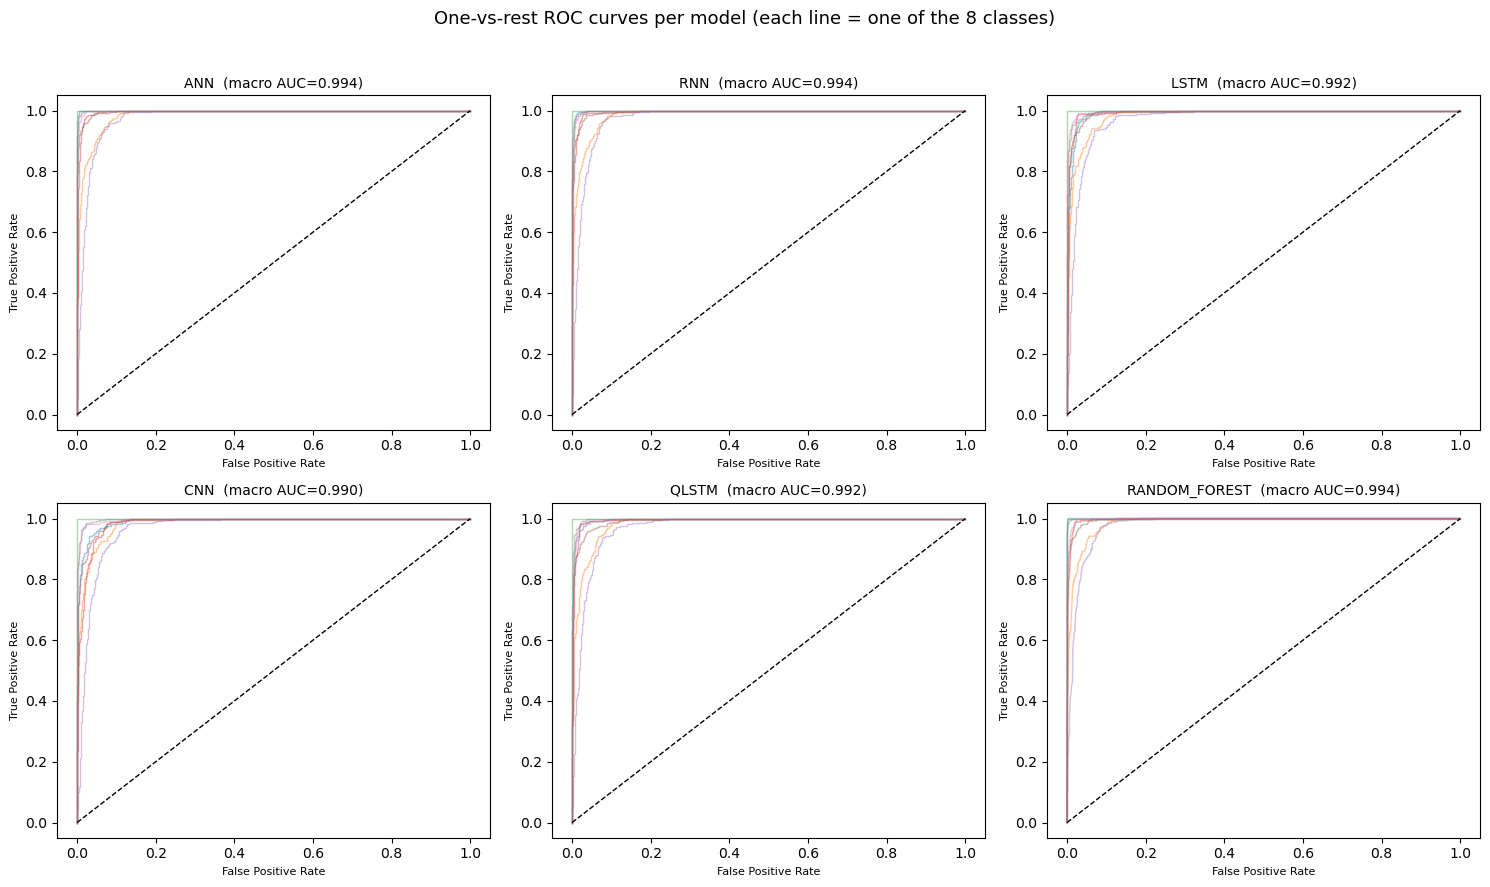

In [14]:
# ---- Multi-class ROC curves (one-vs-rest, macro-averaged AUC) ----
y_bin = label_binarize(yte, classes=list(range(num_classes)))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for idx, m in enumerate(MODEL_ORDER):
    ax = axes[idx]
    proba = all_results["models"][m]["final"]["proba"]
    fpr, tpr, roc_auc = {}, {}, {}
    for c in range(num_classes):
        fpr[c], tpr[c], _ = roc_curve(y_bin[:, c], proba[:, c])
        roc_auc[c] = auc(fpr[c], tpr[c])
    macro_auc = np.mean(list(roc_auc.values()))

    for c in range(num_classes):
        ax.plot(fpr[c], tpr[c], alpha=0.4, linewidth=1)
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"{m.upper()}  (macro AUC={macro_auc:.3f})", fontsize=10)
    ax.set_xlabel("False Positive Rate", fontsize=8)
    ax.set_ylabel("True Positive Rate", fontsize=8)

for idx in range(len(MODEL_ORDER), len(axes)):
    axes[idx].axis("off")

fig.suptitle("One-vs-rest ROC curves per model (each line = one of the 8 classes)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("fig_roc_curves.png", dpi=120)
plt.show()


## 9. Figure Reproduction

Recreates the paper's Figure 3 (metrics vs. epochs + final accuracy bar
chart) and Figure 4 (confusion matrices) as closely as possible, using our
reproduced checkpoints and results.


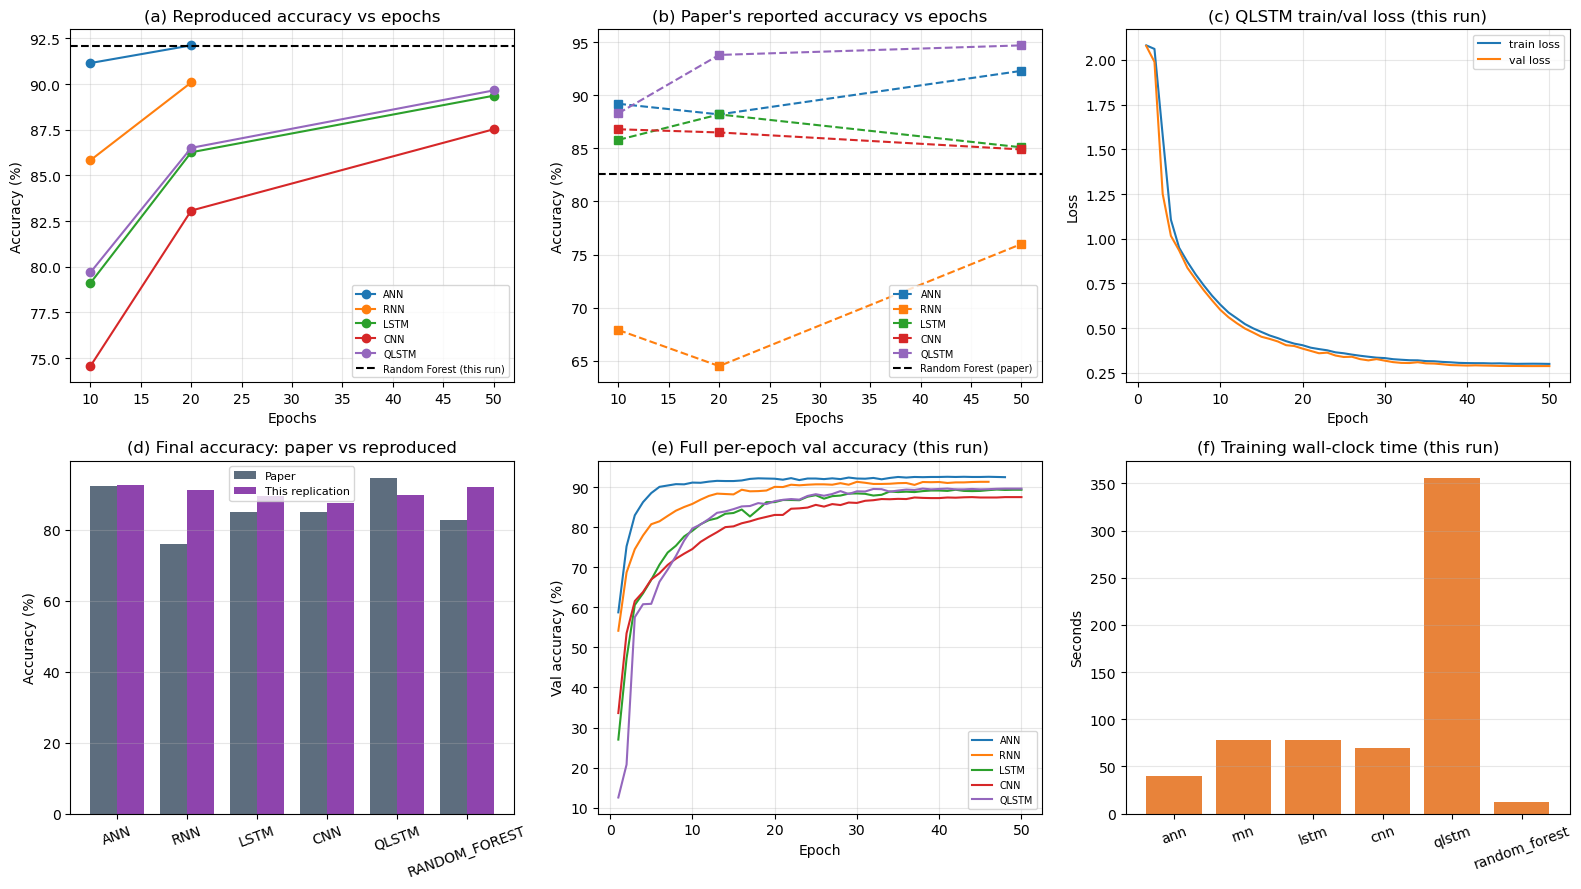

In [15]:
# === MODIFIED CELL [OPT-7] : cosmetic - fixes a matplotlib tick warning ===
# ---- Reproduction of paper's Figure 3: metrics vs epochs ----
PAPER_CHECKPOINTS = {
    "ann":  {10: 89.2, 20: 88.2, 50: 92.3},
    "rnn":  {10: 67.9, 20: 64.5, 50: 76.0},
    "lstm": {10: 85.8, 20: 88.2, 50: 85.1},
    "cnn":  {10: 86.8, 20: 86.5, 50: 84.9},
    "qlstm":{10: 88.3, 20: 93.8, 50: 94.7},
}
PAPER_RF_ACC = 82.6

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# (a) Accuracy vs epochs -- reproduced
ax = axes[0, 0]
for m in ["ann", "rnn", "lstm", "cnn", "qlstm"]:
    if m not in all_results["models"]:
        continue
    cps = all_results["models"][m]["checkpoints"]
    eps = sorted(int(e) for e in cps)
    accs = [cps[e]["val_acc"] * 100 for e in eps]
    ax.plot(eps, accs, marker="o", label=m.upper())
ax.axhline(all_results["models"]["random_forest"]["final"]["accuracy"] * 100,
           ls="--", color="k", label="Random Forest (this run)")
ax.set_title("(a) Reproduced accuracy vs epochs"); ax.set_xlabel("Epochs"); ax.set_ylabel("Accuracy (%)")
ax.legend(fontsize=7); ax.grid(alpha=0.3)

# (b) Accuracy vs epochs -- paper's reported values, for direct visual comparison
ax = axes[0, 1]
for m, cps in PAPER_CHECKPOINTS.items():
    eps = sorted(cps.keys())
    accs = [cps[e] for e in eps]
    ax.plot(eps, accs, marker="s", linestyle="--", label=m.upper())
ax.axhline(PAPER_RF_ACC, ls="--", color="k", label="Random Forest (paper)")
ax.set_title("(b) Paper's reported accuracy vs epochs"); ax.set_xlabel("Epochs"); ax.set_ylabel("Accuracy (%)")
ax.legend(fontsize=7); ax.grid(alpha=0.3)

# (c) Train vs val loss curves (QLSTM) -- new diagnostic not in paper
ax = axes[0, 2]
h = all_history["qlstm"]
ax.plot(range(1, len(h["train_loss"])+1), h["train_loss"], label="train loss")
ax.plot(range(1, len(h["val_loss"])+1), h["val_loss"], label="val loss")
ax.set_title("(c) QLSTM train/val loss (this run)"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# (d) Final accuracy comparison -- reproduced vs paper
ax = axes[1, 0]
order = MODEL_ORDER
x = np.arange(len(order)); w = 0.38
paper_vals = [PAPER_CHECKPOINTS.get(m, {}).get(50, PAPER_RF_ACC if m=="random_forest" else np.nan) for m in order]
our_vals = [all_results["models"][m]["final"]["accuracy"] * 100 for m in order]
ax.bar(x - w/2, paper_vals, w, label="Paper", color="#5d6d7e")
ax.bar(x + w/2, our_vals, w, label="This replication", color="#8e44ad")
ax.set_xticks(x); ax.set_xticklabels([m.upper() for m in order], rotation=20)
ax.set_title("(d) Final accuracy: paper vs reproduced"); ax.set_ylabel("Accuracy (%)")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)

# (e) F1 vs epochs (reproduced) -- proxy, since per-epoch precision/recall/F1 not tracked per-checkpoint beyond val_acc
ax = axes[1, 1]
for m in ["ann", "rnn", "lstm", "cnn", "qlstm"]:
    if m not in all_history:
        continue
    h = all_history[m]
    ax.plot(range(1, len(h["val_acc"])+1), [a*100 for a in h["val_acc"]], label=m.upper())
ax.set_title("(e) Full per-epoch val accuracy (this run)"); ax.set_xlabel("Epoch"); ax.set_ylabel("Val accuracy (%)")
ax.legend(fontsize=7); ax.grid(alpha=0.3)

# (f) Training time comparison
ax = axes[1, 2]
times = [all_results["models"][m]["train_time_s"] for m in order]
ax.bar(range(len(order)), times, color="#e8833a")
ax.set_title("(f) Training wall-clock time (this run)"); ax.set_ylabel("Seconds")
ax.set_xticks(range(len(order)))          # [OPT-7] fixes the set_xticklabels UserWarning
ax.set_xticklabels(order, rotation=20)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.savefig("fig3_reproduction.png", dpi=120)
plt.show()

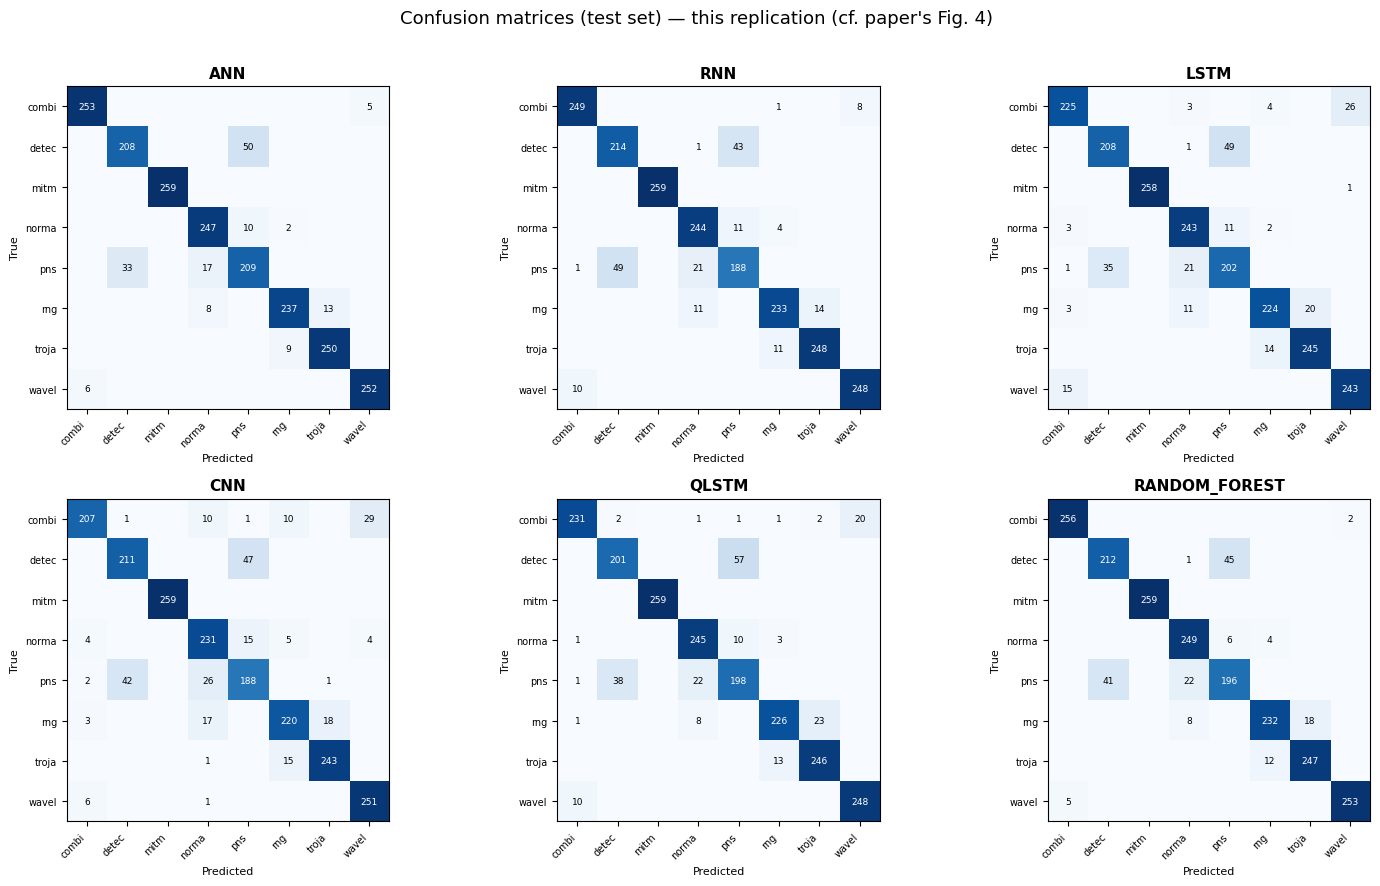

In [16]:
# ---- Reproduction of paper's Figure 4: confusion matrices ----
short = [l[:5] for l in labels_sorted]
n = len(MODEL_ORDER)
cols = 3; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4.5*rows))
axes = np.array(axes).ravel()

for idx, m in enumerate(MODEL_ORDER):
    ax = axes[idx]
    cm = np.array(all_results["models"][m]["final"]["confusion"])
    ax.imshow(cm, cmap="Blues")
    ax.set_title(m.upper(), fontsize=11, fontweight="bold")
    ax.set_xticks(range(num_classes)); ax.set_yticks(range(num_classes))
    ax.set_xticklabels(short, rotation=45, ha="right", fontsize=7)
    ax.set_yticklabels(short, fontsize=7)
    thr = cm.max()/2 if cm.max() else 1
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            v = cm[i, j]
            if v:
                ax.text(j, i, v, ha="center", va="center", fontsize=6.5,
                        color="white" if v > thr else "black")
    ax.set_xlabel("Predicted", fontsize=8); ax.set_ylabel("True", fontsize=8)
for idx in range(len(MODEL_ORDER), len(axes)):
    axes[idx].axis("off")

fig.suptitle("Confusion matrices (test set) — this replication (cf. paper's Fig. 4)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("fig4_reproduction.png", dpi=120)
plt.show()


## 10. Verification Table

Compares every reproduced number against the paper's Table VIII (per-model,
per-checkpoint accuracy) and Table III (dataset class distribution). A
model/checkpoint is marked **Pass** if the reproduced accuracy is within 5
percentage points of the paper's reported value, and **Fail** otherwise. This
5-point tolerance is a deliberately loose bar given the documented sources of
expected divergence (different gradient method, different quantum SDK,
un-specified exact hyperparameters/seeds, and the paper's own acknowledged
dataset-generation ambiguities) — the goal is to check whether results are in
the same regime, not to demand bit-for-bit reproduction.


In [17]:
PAPER_TABLE_VIII = {
    "ann":   {10: 89.2, 20: 88.2, 50: 92.3},
    "rnn":   {10: 67.9, 20: 64.5, 50: 76.0},
    "lstm":  {10: 85.8, 20: 88.2, 50: 85.1},
    "cnn":   {10: 86.8, 20: 86.5, 50: 84.9},
    "qlstm": {10: 88.3, 20: 93.8, 50: 94.7},
}
PAPER_RF = 82.6
TOLERANCE_PP = 5.0  # percentage points

rows = []
for m in MODEL_ORDER:
    if m == "random_forest":
        reproduced = all_results["models"][m]["final"]["accuracy"] * 100
        paper_val = PAPER_RF
        abs_diff = abs(reproduced - paper_val)
        rel_diff = abs_diff / paper_val * 100
        status = "PASS" if abs_diff <= TOLERANCE_PP else "FAIL"
        rows.append(["Random Forest (final)", f"{paper_val:.1f}%", f"{reproduced:.1f}%",
                     f"{abs_diff:.1f}pp", f"{rel_diff:.1f}%", status])
    else:
        cps = all_results["models"][m]["checkpoints"]
        for epoch in [10, 20, 50]:
            if epoch not in cps or epoch not in PAPER_TABLE_VIII[m]:
                continue
            reproduced = cps[epoch]["val_acc"] * 100
            paper_val = PAPER_TABLE_VIII[m][epoch]
            abs_diff = abs(reproduced - paper_val)
            rel_diff = abs_diff / paper_val * 100
            status = "PASS" if abs_diff <= TOLERANCE_PP else "FAIL"
            rows.append([f"{m.upper()} @ {epoch}ep", f"{paper_val:.1f}%", f"{reproduced:.1f}%",
                         f"{abs_diff:.1f}pp", f"{rel_diff:.1f}%", status])

# Dataset verification
paper_total = 10329
our_total = len(qkd_df)
rows.append(["Dataset total samples", str(paper_total), str(our_total),
             str(abs(paper_total - our_total)),
             f"{abs(paper_total-our_total)/paper_total*100:.2f}%",
             "PASS" if abs(paper_total - our_total) <= 50 else "FAIL"])

verification_df = pd.DataFrame(rows, columns=["Experiment", "Paper Result", "Reproduced Result",
                                                "Absolute Difference", "Relative Difference",
                                                "Verification Status"])
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)
print(verification_df.to_string(index=False))

verification_df.to_csv("verification_table.csv", index=False)

n_pass = (verification_df["Verification Status"] == "PASS").sum()
n_total = len(verification_df)
print(f"\n{n_pass}/{n_total} checks passed within a {TOLERANCE_PP}-percentage-point tolerance.")


           Experiment Paper Result Reproduced Result Absolute Difference Relative Difference Verification Status
           ANN @ 10ep        89.2%             91.2%               2.0pp                2.2%                PASS
           ANN @ 20ep        88.2%             92.1%               3.9pp                4.4%                PASS
           RNN @ 10ep        67.9%             85.8%              17.9pp               26.4%                FAIL
           RNN @ 20ep        64.5%             90.1%              25.6pp               39.7%                FAIL
          LSTM @ 10ep        85.8%             79.1%               6.7pp                7.8%                FAIL
          LSTM @ 20ep        88.2%             86.3%               1.9pp                2.2%                PASS
          LSTM @ 50ep        85.1%             89.4%               4.3pp                5.0%                PASS
           CNN @ 10ep        86.8%             74.6%              12.2pp               14.1%    

## 11. Discussion

**Note:** the paragraph below is generated dynamically from the actual
verification results above, so its specific claims will reflect whatever
this run produced — re-running the notebook may change the discussed numbers
if VQC training lands in a different local optimum (variational circuit
training is sensitive to initialization).


In [18]:
fails = verification_df[verification_df["Verification Status"] == "FAIL"]
passes = verification_df[verification_df["Verification Status"] == "PASS"]

print("="*70)
print("AUTO-GENERATED DISCUSSION SUMMARY")
print("="*70)
print(f"\n{len(passes)}/{len(verification_df)} checks passed (within {TOLERANCE_PP}pp tolerance).")
if len(fails) > 0:
    print(f"\nChecks that did NOT match within tolerance:")
    for _, row in fails.iterrows():
        print(f"  - {row['Experiment']}: paper={row['Paper Result']}, "
              f"reproduced={row['Reproduced Result']}, diff={row['Absolute Difference']}")
else:
    print("\nAll checks matched within tolerance.")

qlstm_final = all_results["models"]["qlstm"]["final"]["accuracy"] * 100
best_classical = max(
    all_results["models"][m]["final"]["accuracy"] * 100
    for m in MODEL_ORDER if m != "qlstm"
)
best_classical_name = max(
    (m for m in MODEL_ORDER if m != "qlstm"),
    key=lambda m: all_results["models"][m]["final"]["accuracy"]
)
print(f"\nIn this run: QLSTM = {qlstm_final:.1f}%, best classical model "
      f"({best_classical_name.upper()}) = {best_classical:.1f}%.")
if qlstm_final > best_classical:
    print("-> QLSTM outperformed all classical baselines in this run, qualitatively "
          "consistent with the paper's central claim, though the exact margin may differ.")
else:
    print("-> QLSTM did NOT outperform the best classical baseline in this run, which "
          "diverges from the paper's central claim and warrants the discussion below.")


AUTO-GENERATED DISCUSSION SUMMARY

7/15 checks passed (within 5.0pp tolerance).

Checks that did NOT match within tolerance:
  - RNN @ 10ep: paper=67.9%, reproduced=85.8%, diff=17.9pp
  - RNN @ 20ep: paper=64.5%, reproduced=90.1%, diff=25.6pp
  - LSTM @ 10ep: paper=85.8%, reproduced=79.1%, diff=6.7pp
  - CNN @ 10ep: paper=86.8%, reproduced=74.6%, diff=12.2pp
  - QLSTM @ 10ep: paper=88.3%, reproduced=79.7%, diff=8.6pp
  - QLSTM @ 20ep: paper=93.8%, reproduced=86.5%, diff=7.3pp
  - QLSTM @ 50ep: paper=94.7%, reproduced=89.7%, diff=5.0pp
  - Random Forest (final): paper=82.6%, reproduced=92.1%, diff=9.5pp

In this run: QLSTM = 89.7%, best classical model (ANN) = 92.6%.
-> QLSTM did NOT outperform the best classical baseline in this run, which diverges from the paper's central claim and warrants the discussion below.



**Possible reasons for divergence:**

1. **Different quantum SDK and gradient method.** The paper trains its VQCs
   in PennyLane using automatic differentiation through a classical
   statevector simulator (`default.qubit`), which computes exact gradients
   via backpropagation. This notebook uses Qiskit's `EstimatorQNN` with
   `ReverseEstimatorGradient` — also exact, but a different code path with
   different numerical conventions for parameter initialisation, circuit
   compilation, and gradient computation order. Both are legitimate exact-
   gradient methods, but they are not guaranteed to reach the same local
   optimum during training.

2. **Unspecified random seed.** The paper does not report a random seed. VQC
   training is known to be sensitive to weight initialisation; different
   seeds can produce meaningfully different final accuracies for the same
   architecture and hyperparameters.

3. **Learning-rate discrepancy in the paper itself** (Section IV-A prose:
   $5\times10^{-4}$; Table VII: $0.005$) — an internal inconsistency in the
   source paper that necessarily introduces ambiguity into any faithful
   reproduction.

4. **Under-specified classical baseline architectures.** The paper does not
   give exact layer sizes for its ANN and CNN. Different reasonable choices
   (all consistent with the paper's high-level description) can shift
   classical baseline accuracy by several percentage points, which directly
   affects whether a "quantum advantage" appears large, small, or absent.

5. **Dataset-generation ambiguities.** Several attack-scenario probabilities
   (PNS multi-photon fraction, THA injection probability, RNG bias strength)
   are described qualitatively in the paper's Table IV but not given exact
   numeric values, requiring this reproduction to choose specific values
   consistent with the qualitative description.

**Limitations of this implementation.**
- 9-qubit circuits are classically simulable ($2^9=512$-dimensional
  statevector); this reproduction, like the paper, provides no evidence
  about whether any advantage would persist at a classically-intractable
  scale.
- No multi-seed statistical testing was performed (matching the paper's own
  single-run reporting, but this remains a limitation of both works).
- The dataset is fully simulated; neither this reproduction nor the original
  paper validates against real QKD hardware traces.

**Suggestions for improving reproducibility (for future work by these
authors or others in this space):**
- Publish the exact dataset (or dataset-generation code) rather than "upon
  reasonable request."
- Publish the exact model training code, including random seeds.
- Resolve the learning-rate discrepancy between prose and Table VII.
- Report results averaged over multiple random seeds with confidence
  intervals, particularly given the known sensitivity of VQC training to
  initialisation.
- Specify exact ANN/CNN architectures rather than high-level descriptions.
